## 1: Imports and Setup

In [8]:
import matplotlib.pyplot as plt
import numpy as np
# Import style settings and helpers from your local toolkit
from vizlib import PALETTE, save_fig, style_defaults
import time
from IPython.display import display, clear_output

In [3]:
style_defaults()

# Grid dimensions and target configuration
ROWS, COLS = 12, 18
TARGET = "3"
N_TARGETS = 9
SEED = 1947

## 2: Helper Functions

In [6]:
def make_grid(seed=SEED):
    rng = np.random.default_rng(seed)
    others = [d for d in "0123456789" if d != TARGET]
    grid = np.array([[rng.choice(others) for _ in range(COLS)]
                     for _ in range(ROWS)], dtype=object)
    flat = rng.choice(ROWS * COLS, size=N_TARGETS, replace=False)
    for k in flat:
        grid[k // COLS, k % COLS] = TARGET
    return grid

def draw(ax, grid, title, colour=False, size=False, shape=False):
    ax.set_xlim(-0.5, COLS - 0.5)
    ax.set_ylim(-0.5, ROWS - 0.5)
    ax.invert_yaxis()
    ax.axis("off")
    ax.set_title(title, fontsize=10.5, loc="left")
    
    for r in range(ROWS):
        for c in range(COLS):
            d = grid[r, c]
            hit = d == TARGET
            if shape and hit:
                ax.add_patch(plt.Circle((c, r), 0.40, fill=False,
                                        edgecolor=PALETTE["ink"], lw=1.6))
            ax.text(c, r, d, ha="center", va="center",
                    fontsize=15 if (size and hit) else 11,
                    fontweight="bold" if (size and hit) else "normal",
                    color=PALETTE["highlight"] if (colour and hit)
                    else PALETTE["ink"])

## 3: Build the Four-Panel Experiment Figure

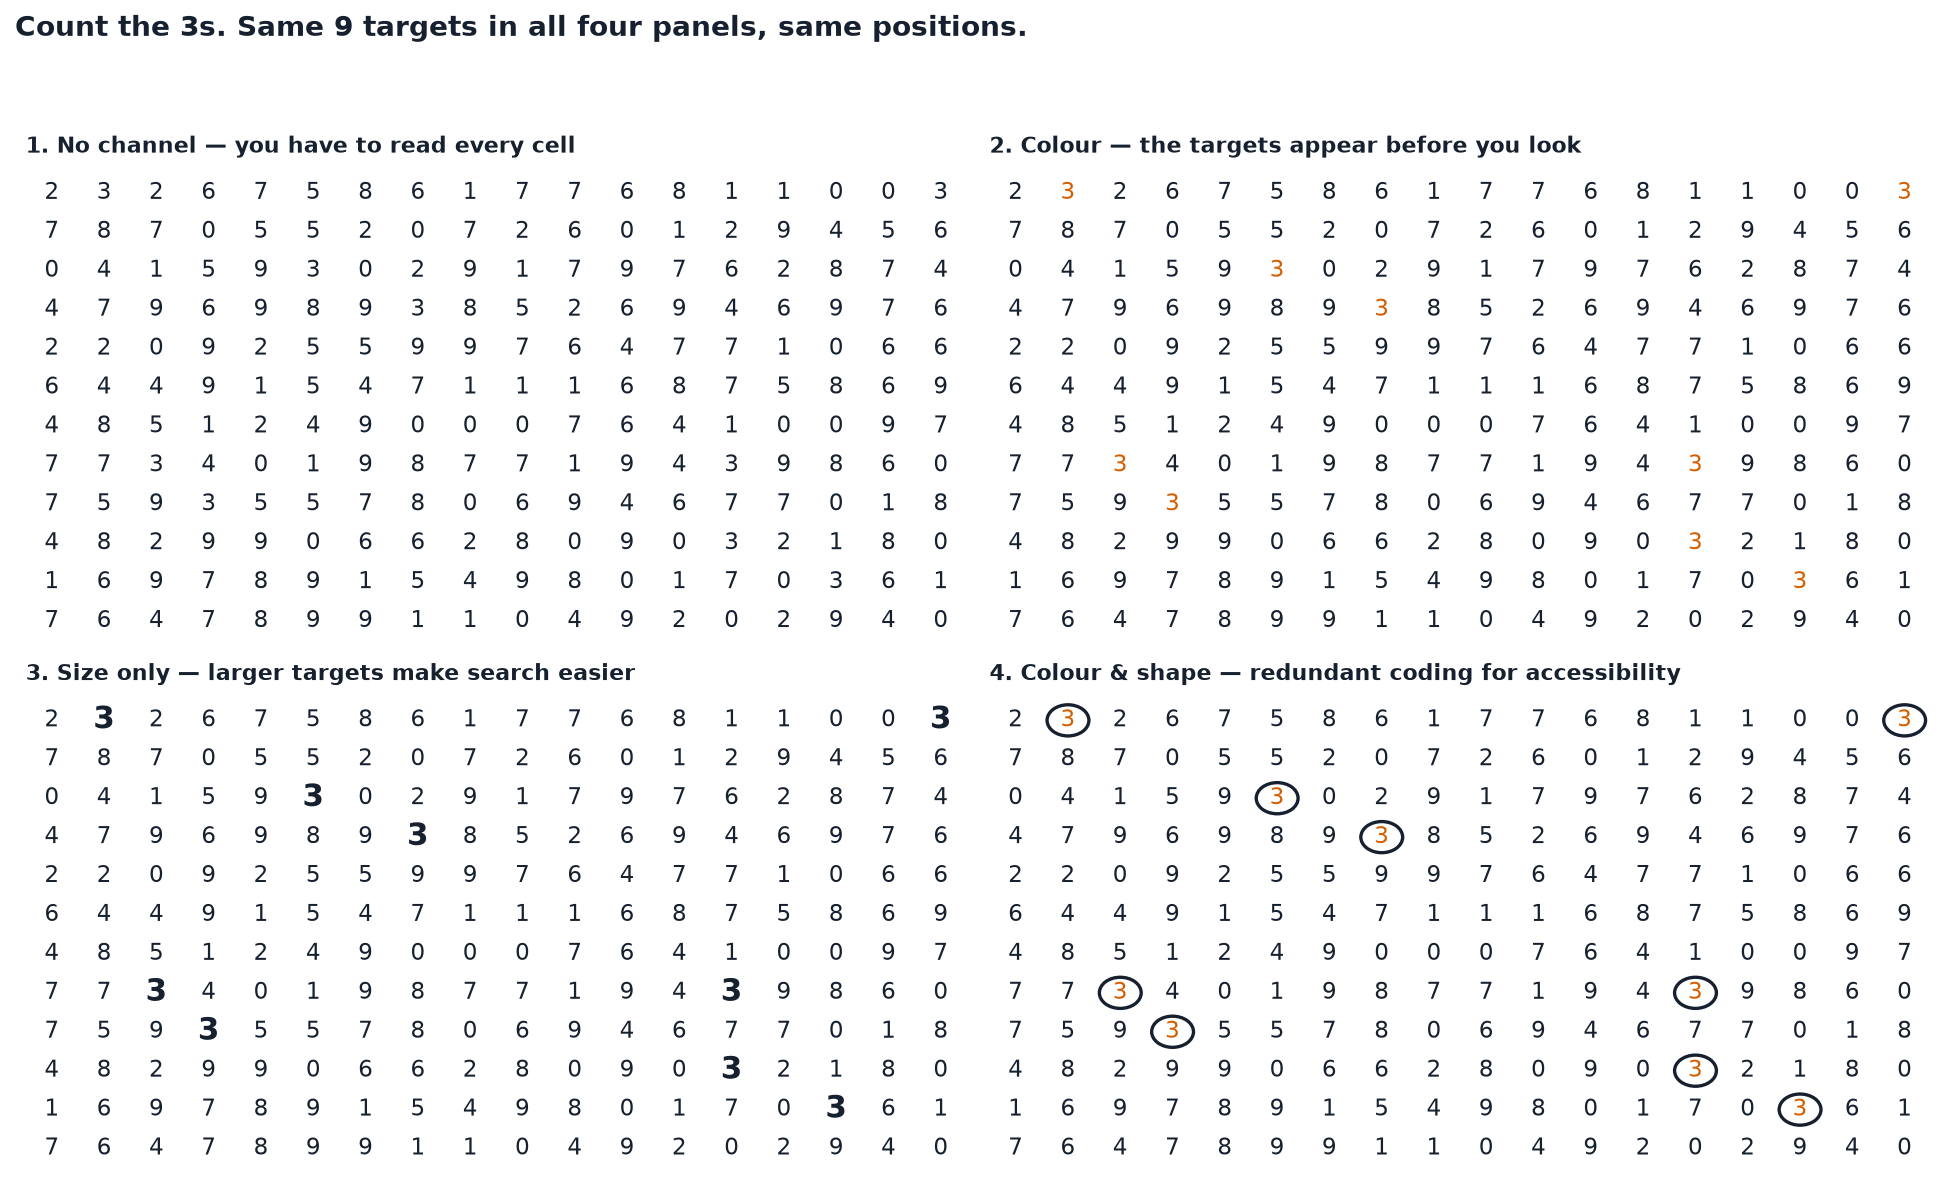

In [21]:
grid = make_grid()
fig, ax = plt.subplots(2, 2, figsize=(13.0, 8.0))

# Panel 1: No visual channel (slow serial search)[cite: 31]
draw(ax[0, 0], grid, "1. No channel — you have to read every cell")

# Panel 2: Colour channel (instant preattentive pop-out)[cite: 31]
draw(ax[0, 1], grid, "2. Colour — the targets appear before you look", colour=True)

# Panel 3: Size channel only (completed task)[cite: 31]
draw(ax[1, 0], grid, "3. Size only — larger targets make search easier", size=True)

# Panel 4: Redundant coding (Colour AND Shape together)[cite: 31]
draw(ax[1, 1], grid, "4. Colour & shape — redundant coding for accessibility", colour=True, shape=True)

fig.suptitle(f"Count the {TARGET}s. Same {N_TARGETS} targets in all four panels, same positions.",
             x=0.006, ha="left", fontsize=13.5, fontweight="bold", color=PALETTE["ink"])
fig.tight_layout(rect=[0, 0, 1, 0.94])

# Display directly inside your Jupyter notebook
plt.show()

In [12]:
# Run this ONCE to initialize your master storage list
master_data = []

## 4: Interactive Data Collection (Run this for each classmate)

In [17]:
import time
from IPython.display import clear_output

panels = [
    {"id": 0, "name": "1. None", "kwargs": {}},
    {"id": 1, "name": "2. Colour", "kwargs": {"colour": True}},
    {"id": 2, "name": "3. Size", "kwargs": {"size": True}},
    {"id": 3, "name": "4. Both", "kwargs": {"colour": True, "shape": True}}
]

participant_name = input("Enter classmate's name or ID: ")
print(f"\nGet ready to test {participant_name}. Show them 4 panels in random order.")
input("Press Enter when ready to start...")

rng_participant = np.random.default_rng()
shuffled_panels = rng_participant.permutation(panels)
collected_times = [0.0] * 4

for idx, panel in enumerate(shuffled_panels):
    clear_output(wait=False)
    fig_single, ax_single = plt.subplots(figsize=(6, 4))
    draw(ax_single, grid, panel["name"], **panel["kwargs"])
    plt.tight_layout()
    plt.show()
    
    orig_index = panel["id"]
    t = float(input(f"[{idx+1}/4] Time taken for '{panel['name']}' (in seconds): "))
    collected_times[orig_index] = t
    plt.close(fig_single)

# Automatically add this classmate's scores to the list
master_data.append(collected_times)

clear_output(wait=False)
print(f"Successfully recorded data for {participant_name}!")
print(f"Total classmates tested so far: {len(master_data)} / 5")
print("Current data array:\n", np.array(master_data))

Successfully recorded data for 007!
Total classmates tested so far: 5 / 5
Current data array:
 [[24.  9.  4.  5.]
 [27.  9.  3.  5.]
 [27.  8.  5.  5.]
 [28.  8.  3.  4.]
 [27.  9.  4.  4.]]


## 5: Final Chart with Your Real Data

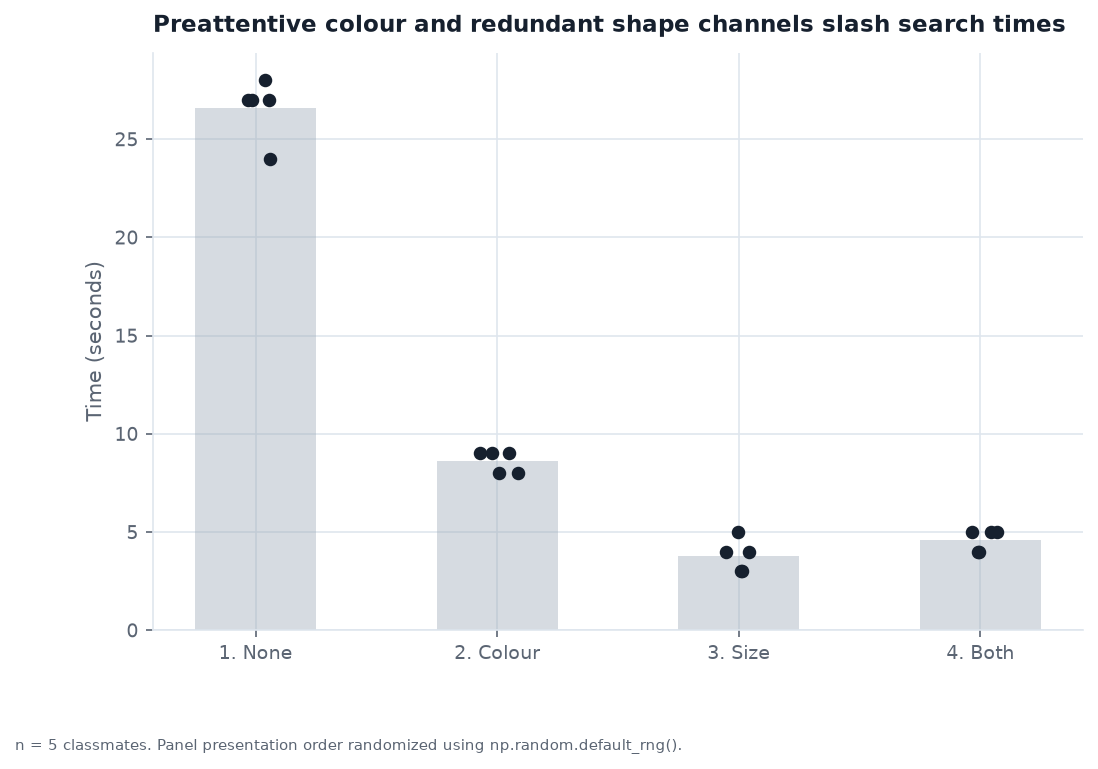

In [19]:
# Automatically uses your collected real data from the master list
real_participant_times = np.array(master_data)

panel_names = ["1. None", "2. Colour", "3. Size", "4. Both"]
mean_times = real_participant_times.mean(axis=0)

fig_exp, ax_exp = plt.subplots(figsize=(8, 5))
ax_exp.bar(panel_names, mean_times, color=PALETTE["muted"], alpha=0.4, width=0.5, edgecolor="none")

for i in range(4):
    x_jitter = np.random.normal(i, 0.04, size=len(real_participant_times))
    ax_exp.scatter(x_jitter, real_participant_times[:, i], color=PALETTE["ink"], zorder=3, s=30)

ax_exp.set_ylabel("Time (seconds)")
ax_exp.set_ylim(bottom=0)
ax_exp.set_title("Preattentive colour and redundant shape channels slash search times", fontsize=11, fontweight="bold", loc="left")

save_fig(fig_exp, "popout_experiment_results.png",
         f"n = {len(real_participant_times)} classmates. Panel presentation order randomized using np.random.default_rng().")
plt.show()
